<a href="https://colab.research.google.com/github/brittanybee-alt/Capstone-Project-Three/blob/main/Capstone_Three_Modeling_%5BBrittany_Barrion%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Three, Step 5: Modeling
## Investigating Fatigue-Related Aviation Safety Reports Through Statistical Analysis and Natural Language Processing

**Author:** Brittany | Springboard Data Science Career Track, Capstone Three

**Research question:** What statistical patterns and recurring narrative themes characterize fatigue-related aviation safety reports submitted to NASA's Aviation Safety Reporting System (ASRS) between 2009 and 2025?

**Input:** the training and testing data created in `03_Preprocessing.ipynb`

**Goal:** build three different topic models, tune them, define the metrics used to compare them, and choose the best final model. Then use the final model's themes to answer the research question, connecting each theme to flight phase, time of day, reporter role and mission.

| Section | What happens |
|---|---|
| 1 | Guiding questions: response variable type, time series |
| 2 | Load the development data |
| 3 | Define the evaluation metrics |
| 4 | Model 1: NMF (tuned over number of topics) |
| 5 | Model 2: LDA (tuned over number of topics and topic-mixing prior) |
| 6 | Model 3: K-Means clustering (tuned over number of clusters) |
| 7 | Compare the models and choose the final one |
| 8 | Interpret the final model's themes |
| 9 | Connect themes to report characteristics (integration) |
| 10 | Integration model: can report characteristics predict the theme? |
| 11 | Save the final model and metrics |

## 1. Guiding Questions

**Is the response variable continuous or categorical?** There is **no observed response variable**. The project is exploratory, so there is no labeled outcome to predict. The models are **unsupervised**: they find the *hidden* themes in the narratives. Each report's theme is a **categorical** variable discovered by the model (and, more precisely, a *mix* of themes with weights). For the integration model in Section 10, that discovered theme becomes a categorical response, so a **classification** model (multinomial logistic regression) is the right tool there.

**Does the data involve a time series or forecasting?** **No.** I'm not forecasting future reports, so the random, phase-stratified train/test split from Step 4 is appropriate. Year is still used *descriptively*, to see whether themes have changed over time (Section 9.4).

**Why these three models?** Each one represents a different way of finding themes in text:

| Model | Idea | Input | Each report gets |
|---|---|---|---|
| **NMF** (Non-negative Matrix Factorization) | Splits the TF-IDF matrix into "reports × topics" and "topics × words" pieces, using only non-negative weights, so topics add up like ingredients | TF-IDF | a *mix* of topics |
| **LDA** (Latent Dirichlet Allocation) | A probability model: each report is a mix of topics, and each topic is a probability distribution over words | word counts | a *mix* of topics (probabilities) |
| **K-Means** | Groups reports with similar TF-IDF vectors into clusters, and a cluster's center shows its typical words | TF-IDF | exactly *one* cluster |

NMF and LDA were the two candidates named in the project proposal. K-Means is a simpler baseline: if the topic models can't beat simple clustering, they aren't adding much.

### 0. Setup

In [5]:
import os
import re
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import sparse, stats
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

PROCESSED_DIR = "data/processed"
MODEL_DIR = "models"
FIG_DIR = "figures"
for folder in [PROCESSED_DIR, MODEL_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)

def save(fig_name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, fig_name), dpi=150)
    plt.show()
    plt.close("all")

## 2. Load the Development Data
These files were all created by `03_Preprocessing.ipynb`. Run that notebook first in the same Colab session.

In [6]:
needed = ["/content/X_tfidf_train.npz", "/content/X_tfidf_test.npz", "/content/X_count_train.npz", "/content/X_count_test.npz",
          "/content/X_struct_train.csv", "/content/X_struct_test.csv", "/content/train_index.csv", "/content/test_index.csv",
          "/content/asrs_fatigue_preprocessed.csv"]
missing = [f for f in needed if not os.path.exists(os.path.join(PROCESSED_DIR, f))]
assert not missing, f"Missing {missing}. Run 03_Preprocessing.ipynb first (same Colab session)."

X_tfidf_train = sparse.load_npz(os.path.join(PROCESSED_DIR, "/content/X_tfidf_train.npz"))
X_tfidf_test = sparse.load_npz(os.path.join(PROCESSED_DIR, "/content/X_tfidf_test.npz"))
X_count_train = sparse.load_npz(os.path.join(PROCESSED_DIR, "/content/X_count_train.npz"))
X_count_test = sparse.load_npz(os.path.join(PROCESSED_DIR, "/content/X_count_test.npz"))
X_struct_train = pd.read_csv(os.path.join(PROCESSED_DIR, "/content/X_struct_train.csv"))
X_struct_test = pd.read_csv(os.path.join(PROCESSED_DIR, "/content/X_struct_test.csv"))
train_idx = pd.read_csv(os.path.join(PROCESSED_DIR, "/content/train_index.csv"))["row"].values
test_idx = pd.read_csv(os.path.join(PROCESSED_DIR, "/content/test_index.csv"))["row"].values
df = pd.read_csv(os.path.join(PROCESSED_DIR, "/content/asrs_fatigue_preprocessed.csv"), parse_dates=["date"], low_memory=False)
df["text_lemma"] = df["text_lemma"].fillna("")

tfidf = joblib.load(os.path.join(MODEL_DIR, "/content/tfidf_vectorizer.joblib"))
vocab = tfidf.get_feature_names_out()

print("TF-IDF train/test:", X_tfidf_train.shape, X_tfidf_test.shape)
print("Counts train/test:", X_count_train.shape, X_count_test.shape)
print("Structured train/test:", X_struct_train.shape, X_struct_test.shape)
print("Reports:", len(df), "| vocabulary:", len(vocab))

TF-IDF train/test: (1752, 9925) (439, 9925)
Counts train/test: (1752, 9925) (439, 9925)
Structured train/test: (1752, 42) (439, 42)
Reports: 2191 | vocabulary: 9925


## 3. Evaluation Metrics

Unsupervised models have no "right answer" to score against, so I define metrics that measure whether the themes are **meaningful, distinct, generalizable and stable**. The same metrics are applied to all three models so the comparison is fair.

| Metric | What it measures | How | Better = |
|---|---|---|---|
| **Topic coherence (NPMI), primary metric** | Do a topic's top words actually appear *together* in real narratives? | For each topic's top 10 words, average the *normalized pointwise mutual information* of every word pair, calculated on the **held-out test narratives**. Ranges from −1 (never together) to +1 (always together). | Higher |
| **Topic diversity** | Are the topics different from each other, or do they repeat the same words? | Share of unique words among all topics' top 25 words | Higher (≥ 0.80 is a common threshold) |
| **Stability** | Does the model find the same topics when re-run with different random starts? | Average overlap (Jaccard similarity) of matched topics' top-10 words across 3 random seeds | Higher (1.0 = identical) |
| **Model-specific checks** | LDA: **perplexity** on test data (how surprised the model is by new reports). K-Means: **silhouette score** (how well separated clusters are). | Built into scikit-learn | Lower perplexity / higher silhouette |
| **Human readability** | Can a person name each topic from its top words and example narratives? | Reading top words and representative narratives | Clear, nameable themes |

**Why coherence on the *test* set?** It's the unsupervised version of checking a model on unseen data. A topic whose words co-occur in training reports but *not* in new reports has memorized quirks of the training data. Coherence that holds up on the test set means the theme is real.

**Why not use only perplexity?** Research on topic models has found that perplexity often *disagrees* with human judgments of topic quality. It's also specific to LDA and can't compare different model types. NPMI coherence correlates better with human judgment and works for all three models.

In [7]:
B_test = (X_count_test > 0).astype(np.float32).tocsc()      # which test narratives contain which terms
N_TEST = B_test.shape[0]
DOC_FREQ_TEST = np.asarray(B_test.sum(axis=0)).ravel()

def npmi_coherence(top_terms, B=B_test, doc_freq=DOC_FREQ_TEST, n_docs=N_TEST):
    """Average NPMI over all pairs of a topic's top terms, using document co-occurrence in the reference set."""
    scores = []
    for i in range(len(top_terms)):
        for j in range(i + 1, len(top_terms)):
            a, b = top_terms[i], top_terms[j]
            p_ab = B[:, a].multiply(B[:, b]).sum() / n_docs
            if p_ab == 0:
                scores.append(-1.0)
                continue
            p_a, p_b = doc_freq[a] / n_docs, doc_freq[b] / n_docs
            scores.append(np.log(p_ab / (p_a * p_b)) / -np.log(p_ab))
    return float(np.mean(scores))

def top_term_ids(components, n=10):
    return [np.argsort(-row)[:n] for row in components]

def topic_diversity(components, n=25):
    tops = top_term_ids(components, n)
    return len(set(np.concatenate(tops))) / (n * len(components))

def mean_coherence(components, n=10, **kw):
    return float(np.mean([npmi_coherence(t, **kw) for t in top_term_ids(components, n)]))

def stability(fit_fn, k, seeds=(0, 1, 2), n=10):
    """Average best-match Jaccard similarity of topics' top words across random seeds."""
    runs = [[set(t) for t in top_term_ids(fit_fn(k, s), n)] for s in seeds]
    sims = []
    for a in range(len(runs)):
        for b in range(a + 1, len(runs)):
            sims.append(np.mean([max(len(x & y) / len(x | y) for y in runs[b]) for x in runs[a]]))
    return float(np.mean(sims))

def show_topics(components, n=10):
    return pd.DataFrame({f"Topic {i}": vocab[t] for i, t in enumerate(top_term_ids(components, n))})

K_VALUES = [4, 6, 8, 10, 12, 14]

**How to read NPMI values.** On the test set, around 0.05–0.10 means a topic's words only loosely belong together, and around 0.20 or higher means they reliably appear together in the same narratives.

## 4. Model 1: NMF

**Hyperparameter tuned:** the number of topics, *k* (4 to 14).
**Fixed settings:** `init="nndsvda"` (a deterministic starting point that gives reproducible results; the stability check uses random starts instead), `max_iter=1000`, `random_state=42`.

In [8]:
def fit_nmf(k, seed=42, init="nndsvda"):
    return NMF(n_components=k, init=init, random_state=seed, max_iter=1000).fit(X_tfidf_train)

results = []
nmf_models = {}
for k in K_VALUES:
    start = time.time()
    model = fit_nmf(k)
    nmf_models[k] = model
    results.append({
        "model": "NMF", "k": k, "setting": "default",
        "coherence_test": mean_coherence(model.components_),
        "diversity": topic_diversity(model.components_),
        "stability": stability(lambda kk, s: fit_nmf(kk, s, init="random").components_, k),
        "seconds": round(time.time() - start, 1),
    })
    print({key: (round(v, 3) if isinstance(v, float) else v) for key, v in results[-1].items()})

{'model': 'NMF', 'k': 4, 'setting': 'default', 'coherence_test': 0.172, 'diversity': 0.96, 'stability': 0.97, 'seconds': 3.2}
{'model': 'NMF', 'k': 6, 'setting': 'default', 'coherence_test': 0.217, 'diversity': 0.907, 'stability': 0.758, 'seconds': 4.5}
{'model': 'NMF', 'k': 8, 'setting': 'default', 'coherence_test': 0.221, 'diversity': 0.875, 'stability': 1.0, 'seconds': 6.9}
{'model': 'NMF', 'k': 10, 'setting': 'default', 'coherence_test': 0.222, 'diversity': 0.864, 'stability': 1.0, 'seconds': 13.3}
{'model': 'NMF', 'k': 12, 'setting': 'default', 'coherence_test': 0.219, 'diversity': 0.847, 'stability': 0.89, 'seconds': 5.6}
{'model': 'NMF', 'k': 14, 'setting': 'default', 'coherence_test': 0.226, 'diversity': 0.806, 'stability': 0.785, 'seconds': 14.7}


## 5. Model 2: LDA

**Hyperparameters tuned:**
- the number of topics, *k* (4 to 14);
- `doc_topic_prior` (often called *alpha*), which controls how many topics each report mixes. scikit-learn's default is 1/k. A smaller value (0.1) tells LDA that each report is mostly about a few topics, which often suits focused incident reports.

**Fixed settings:** `learning_method="batch"` (uses all training reports at every step, which is more accurate on a dataset this size), `max_iter=30`, `random_state=42`.

This grid takes a few minutes, because LDA is slower to fit than NMF.

In [9]:
def fit_lda(k, seed=42, alpha=None):
    return LatentDirichletAllocation(n_components=k, doc_topic_prior=alpha, learning_method="batch",
                                     max_iter=30, random_state=seed).fit(X_count_train)

lda_models = {}
for alpha in [None, 0.1]:
    for k in K_VALUES:
        start = time.time()
        model = fit_lda(k, alpha=alpha)
        lda_models[(k, alpha)] = model
        results.append({
            "model": "LDA", "k": k, "setting": "alpha=1/k" if alpha is None else f"alpha={alpha}",
            "coherence_test": mean_coherence(model.components_),
            "diversity": topic_diversity(model.components_),
            "perplexity_test": model.perplexity(X_count_test),
            "seconds": round(time.time() - start, 1),
        })
        print({key: (round(v, 3) if isinstance(v, float) else v) for key, v in results[-1].items()})

{'model': 'LDA', 'k': 4, 'setting': 'alpha=1/k', 'coherence_test': 0.158, 'diversity': 0.83, 'perplexity_test': np.float64(4142.658), 'seconds': 27.4}
{'model': 'LDA', 'k': 6, 'setting': 'alpha=1/k', 'coherence_test': 0.148, 'diversity': 0.733, 'perplexity_test': np.float64(4769.186), 'seconds': 28.6}
{'model': 'LDA', 'k': 8, 'setting': 'alpha=1/k', 'coherence_test': 0.165, 'diversity': 0.685, 'perplexity_test': np.float64(5406.727), 'seconds': 29.8}
{'model': 'LDA', 'k': 10, 'setting': 'alpha=1/k', 'coherence_test': 0.164, 'diversity': 0.656, 'perplexity_test': np.float64(6055.665), 'seconds': 33.5}
{'model': 'LDA', 'k': 12, 'setting': 'alpha=1/k', 'coherence_test': 0.154, 'diversity': 0.647, 'perplexity_test': np.float64(6623.614), 'seconds': 31.8}
{'model': 'LDA', 'k': 14, 'setting': 'alpha=1/k', 'coherence_test': 0.142, 'diversity': 0.606, 'perplexity_test': np.float64(7364.589), 'seconds': 33.1}
{'model': 'LDA', 'k': 4, 'setting': 'alpha=0.1', 'coherence_test': 0.158, 'diversity':

In [10]:
best_lda_key = max(lda_models, key=lambda key: [r["coherence_test"] for r in results
                   if r["model"] == "LDA" and r["k"] == key[0]
                   and r["setting"] == ("alpha=1/k" if key[1] is None else f"alpha={key[1]}")][0])
k_lda, alpha_lda = best_lda_key
lda_stab = stability(lambda kk, s: fit_lda(kk, s, alpha_lda).components_, k_lda)
for r in results:
    if r["model"] == "LDA" and r["k"] == k_lda and r["setting"] == ("alpha=1/k" if alpha_lda is None else f"alpha={alpha_lda}"):
        r["stability"] = lda_stab
print(f"Best LDA setting by test coherence: k = {k_lda}, alpha = {alpha_lda or '1/k'} | stability = {lda_stab:.3f}")

Best LDA setting by test coherence: k = 8, alpha = 1/k | stability = 0.446


**Note on LDA stability.** Because LDA is slow, I measure stability only for its best setting, not for every *k*.

## 6. Model 3: K-Means Clustering

**Hyperparameter tuned:** the number of clusters, *k* (4 to 14). **Fixed settings:** `n_init=10` (runs 10 random starts and keeps the best), `random_state=42`.

A cluster's "top words" are the words with the highest average TF-IDF weight among the reports in it (the cluster center), so the same coherence and diversity metrics apply. K-Means also gets its own **silhouette score**, which measures how much closer each report is to its own cluster than to the next nearest one.

In [11]:
def fit_kmeans(k, seed=42):
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_tfidf_train)

km_models = {}
for k in K_VALUES:
    start = time.time()
    model = fit_kmeans(k)
    km_models[k] = model
    results.append({
        "model": "K-Means", "k": k, "setting": "default",
        "coherence_test": mean_coherence(model.cluster_centers_),
        "diversity": topic_diversity(model.cluster_centers_),
        "stability": stability(lambda kk, s: fit_kmeans(kk, s).cluster_centers_, k),
        "silhouette": silhouette_score(X_tfidf_train, model.labels_, metric="cosine"),
        "seconds": round(time.time() - start, 1),
    })
    print({key: (round(v, 3) if isinstance(v, float) else v) for key, v in results[-1].items()})

{'model': 'K-Means', 'k': 4, 'setting': 'default', 'coherence_test': 0.166, 'diversity': 0.84, 'stability': 0.651, 'silhouette': np.float64(0.015), 'seconds': 2.7}
{'model': 'K-Means', 'k': 6, 'setting': 'default', 'coherence_test': 0.192, 'diversity': 0.82, 'stability': 0.697, 'silhouette': np.float64(0.017), 'seconds': 4.9}
{'model': 'K-Means', 'k': 8, 'setting': 'default', 'coherence_test': 0.206, 'diversity': 0.765, 'stability': 0.723, 'silhouette': np.float64(0.018), 'seconds': 5.5}
{'model': 'K-Means', 'k': 10, 'setting': 'default', 'coherence_test': 0.211, 'diversity': 0.684, 'stability': 0.666, 'silhouette': np.float64(0.015), 'seconds': 8.0}
{'model': 'K-Means', 'k': 12, 'setting': 'default', 'coherence_test': 0.204, 'diversity': 0.653, 'stability': 0.541, 'silhouette': np.float64(0.012), 'seconds': 7.9}
{'model': 'K-Means', 'k': 14, 'setting': 'default', 'coherence_test': 0.206, 'diversity': 0.611, 'stability': 0.519, 'silhouette': np.float64(0.012), 'seconds': 10.0}


## 7. Compare the Models and Choose the Final One

,model,k,setting,coherence_test,diversity,stability,seconds,perplexity_test,silhouette
0,NMF,4,default,0.172,0.960,0.970,3.2,NaN,NaN
1,NMF,6,default,0.217,0.907,0.758,4.5,NaN,NaN
2,NMF,8,default,0.221,0.875,1.000,6.9,NaN,NaN
3,NMF,10,default,0.222,0.864,1.000,13.3,NaN,NaN
4,NMF,12,default,0.219,0.847,0.890,5.6,NaN,NaN
5,NMF,14,default,0.226,0.806,0.785,14.7,NaN,NaN
6,LDA,4,alpha=1/k,0.158,0.830,NaN,27.4,4142.658,NaN
7,LDA,6,alpha=1/k,0.148,0.733,NaN,28.6,4769.186,NaN
8,LDA,8,alpha=1/k,0.165,0.685,0.446,29.8,5406.727,NaN
9,LDA,10,alpha=1/k,0.164,0.656,NaN,33.5,6055.665,NaN


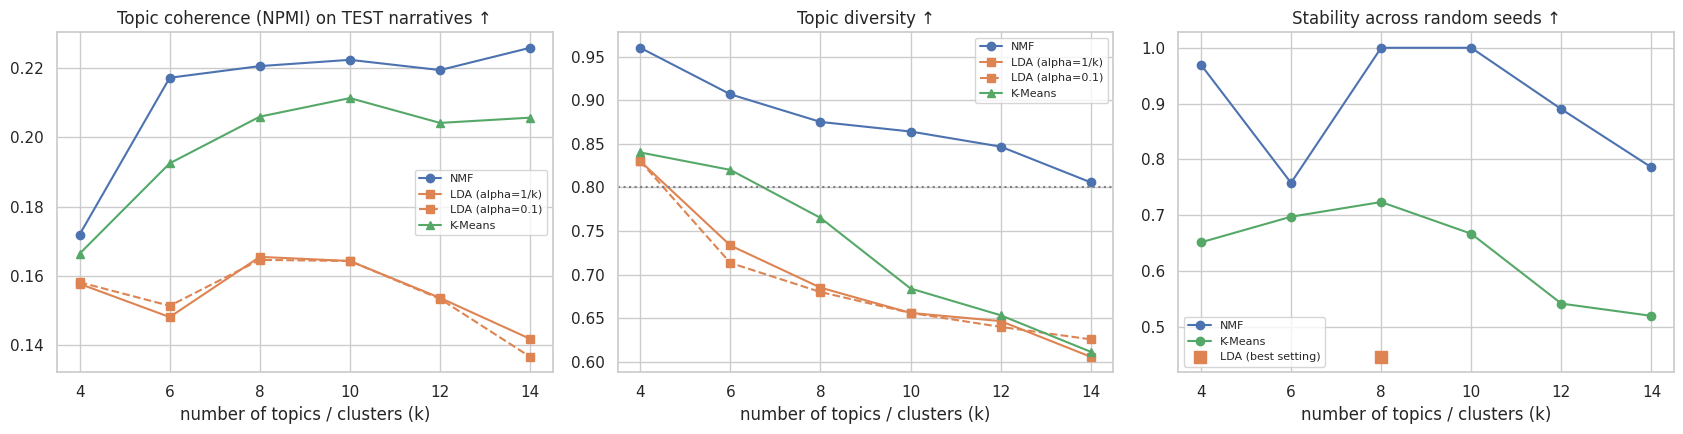

In [12]:
res = pd.DataFrame(results)
display(res.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
styles = {("NMF", "default"): ("#4C72B0", "-o"), ("LDA", "alpha=1/k"): ("#DD8452", "-s"),
          ("LDA", "alpha=0.1"): ("#DD8452", "--s"), ("K-Means", "default"): ("#55A868", "-^")}
for (m, s), (color, fmt) in styles.items():
    sub = res[(res["model"] == m) & (res["setting"] == s)]
    label = m if s == "default" else f"{m} ({s})"
    axes[0].plot(sub["k"], sub["coherence_test"], fmt, color=color, label=label)
    axes[1].plot(sub["k"], sub["diversity"], fmt, color=color, label=label)
axes[0].set_title("Topic coherence (NPMI) on TEST narratives ↑")
axes[1].set_title("Topic diversity ↑")
axes[1].axhline(0.8, ls=":", color="grey")
stab = res.dropna(subset=["stability"])
for m, color in [("NMF", "#4C72B0"), ("K-Means", "#55A868")]:
    sub = stab[stab["model"] == m]
    axes[2].plot(sub["k"], sub["stability"], "-o", color=color, label=m)
lda_point = stab[stab["model"] == "LDA"]
axes[2].scatter(lda_point["k"], lda_point["stability"], color="#DD8452", s=80, marker="s", label="LDA (best setting)", zorder=3)
axes[2].set_title("Stability across random seeds ↑")
for ax in axes:
    ax.set_xlabel("number of topics / clusters (k)")
    ax.legend(fontsize=8)
save("model_01_comparison.png")

In [13]:
best_per_model = (res.sort_values("coherence_test", ascending=False)
                     .groupby("model").head(1)
                     .set_index("model")[["k", "setting", "coherence_test", "diversity", "stability", "perplexity_test", "silhouette"]])
display(best_per_model.round(3))

,k,setting,coherence_test,diversity,stability,perplexity_test,silhouette
model,,,,,,,
NMF,14,default,0.226,0.806,0.785,NaN,NaN
K-Means,10,default,0.211,0.684,0.666,NaN,0.015
LDA,8,alpha=1/k,0.165,0.685,0.446,5406.727,NaN


**What the comparison shows** (numbers from my run; yours should match closely):
- **NMF has the highest test coherence at every k** (0.217–0.226 from k = 6 onward) and the **highest diversity** (0.81–0.96, always above 0.80). It is **perfectly stable (1.0) at k = 8 and k = 10**, meaning different random starts find the same topics.
- **LDA has the lowest coherence** (0.14–0.17), its **diversity drops below 0.80 already at k = 6**, and its best setting (k = 8) has **low stability (0.45)**: re-running it with a different seed gives noticeably different topics. That's a known weakness of LDA on a fairly small collection of long, jargon-heavy documents, where common words spread across all topics. Changing alpha from 1/k to 0.1 made almost no difference.
- **K-Means** sits in between on coherence (up to 0.21), but its diversity falls below 0.80 by k = 8, its stability is moderate (0.52–0.72), and its **silhouette scores are close to 0 (0.01–0.02)**. The reports don't form clean, separate clusters. That makes sense, because one narrative usually mixes several themes (e.g., a tired crew *and* an unstable approach), and forcing each report into exactly one group loses that.

**Decision: NMF is the final model type.** It wins on every metric that applies to all three models.

### 7.1 Choosing the number of topics for NMF
The metrics narrow the choice for NMF to a plateau. I shortlist every *k* whose coherence is within 0.01 of the best NMF score and whose diversity is at least 0.80, then use **readability** to choose among them. This is like the "one-standard-error" logic from model selection: when several options score about the same, choose based on simplicity and usefulness.

In [14]:
nmf_res = res[res["model"] == "NMF"].set_index("k")
shortlist = nmf_res[(nmf_res["coherence_test"] >= nmf_res["coherence_test"].max() - 0.01) & (nmf_res["diversity"] >= 0.80)]
display(shortlist[["coherence_test", "diversity", "stability"]].round(3))

,coherence_test,diversity,stability
k,,,
6,0.217,0.907,0.758
8,0.221,0.875,1.000
10,0.222,0.864,1.000
12,0.219,0.847,0.890
14,0.226,0.806,0.785


In [15]:
for k in [6, 8, 10]:
    print(f"\n=== NMF with k = {k} ===")
    display(show_topics(nmf_models[k].components_, n=8))


=== NMF with k = 6 ===


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5
0,approach,sleep,maintenance,sector,taxiway,altitude
1,visual,rest,engine,traffic,runway,ft
2,final,trip,gate,controller,taxi,atc
3,landing,duty,mechanic,staffing,tower,descent
4,flap,crew,door,working,ground,clearance
5,runway,scheduling,control,shift,clearance,descend
6,go around,fatigued,checklist,position,ramp,restriction
7,around,night,crew,work,hold,fl



=== NMF with k = 8 ===


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7
0,approach,sleep,attendant,sector,taxiway,altitude,maintenance,flap
1,visual,trip,flight attendant,traffic,runway,ft,mechanic,speed
2,visual approach,rest,passenger,controller,taxi,atc,engine,go around
3,runway,duty,gate,staffing,tower,descent,task,around
4,il,fatigued,dispatch,working,ground,clearance,check,gear
5,final,scheduling,crew,position,ramp,restriction,work,landing
6,tower,night,door,shift,clearance,descend,installed,go
7,airport,crew,cabin,work,hold short,fl,part,checklist



=== NMF with k = 10 ===


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9
0,approach,sleep,engine,sector,taxiway,arrival,maintenance,flap,attendant,ft
1,visual,trip,fuel,traffic,runway,atc,mechanic,speed,flight attendant,altitude
2,visual approach,rest,dispatch,controller,taxi,fm,task,go around,door,climb
3,runway,duty,maintenance,staffing,tower,restriction,check,around,passenger,autopilot
4,il,scheduling,gate,working,ground,descent,installed,gear,cabin,msl
5,tower,fatigued,checklist,position,hold short,fl,work,landing,crew,departure
6,final,night,takeoff,shift,ramp,clearance,card,go,fa,altimeter
7,airport,crew,message,work,hold,descend,job,knot,seat,atc


**Readability comparison of k = 6, 8 and 10:**
- **k = 6** mixes two different settings into one topic: *maintenance / mechanic / engine* work and *gate / door / checklist* activity end up together. Its stability is also lower (0.76).
- **k = 8** splits that mixed topic into a clear **maintenance work** theme and a clear **flight attendant, passenger, gate and cabin** theme, and separates **approach and landing configuration** (flaps, speed, go-around, gear) from **visual approach** issues. Every topic can be named from its top words.
- **k = 10** keeps those themes but splits **altitude** into two similar topics (descent and arrival restrictions vs. altitude, climb and autopilot), and adds an engine/fuel/dispatch topic that borrows words from the gate and maintenance themes. Coherence barely changes (0.222 vs. 0.221), so the extra topics add complexity without adding clearly new themes.

**Final decision: NMF with k = 8 topics.** It's the **smallest number of topics on the coherence plateau with perfect stability**, it has high diversity (0.875), and it gives the clearest set of nameable themes. When two options score about the same, the simpler one is preferred.

> **Your decision point:** read the k = 6, 8 and 10 tables above yourself. If you find k = 10's extra topics more useful for the research question, change `FINAL_K` below. Everything after it updates automatically, but you'd need to rewrite the topic labels in Section 8.

In [16]:
FINAL_K = 8
final_model = nmf_models[FINAL_K]
final_row = nmf_res.loc[FINAL_K]
print(f"Final model: NMF, k = {FINAL_K}")
print(f"  test coherence = {final_row['coherence_test']:.3f} | diversity = {final_row['diversity']:.3f} | stability = {final_row['stability']:.3f}")

Final model: NMF, k = 8
  test coherence = 0.221 | diversity = 0.875 | stability = 1.000


### 7.2 Does the final model generalize? Train vs. test
If a model only memorized the training narratives, its topics would fit the training data much better than the test data. I compare two things:
1. **Coherence** of the same topics measured on training vs. test narratives.
2. **Reconstruction error**: how well each report's TF-IDF vector is rebuilt from its topic mix, averaged per report.

In [17]:
B_train = (X_count_train > 0).astype(np.float32).tocsc()
coh_train = mean_coherence(final_model.components_, B=B_train,
                           doc_freq=np.asarray(B_train.sum(axis=0)).ravel(), n_docs=B_train.shape[0])

def recon_error_per_doc(model, X):
    W = model.transform(X)
    diff = X - sparse.csr_matrix(W @ model.components_)
    return np.sqrt(np.asarray(diff.multiply(diff).sum(axis=1)).ravel()).mean()

gen = pd.DataFrame({
    "train": [coh_train, recon_error_per_doc(final_model, X_tfidf_train)],
    "test": [final_row["coherence_test"], recon_error_per_doc(final_model, X_tfidf_test)],
}, index=["coherence (NPMI) ↑", "reconstruction error per report ↓"]).round(3)
display(gen)

,train,test
coherence (NPMI) ↑,0.243,0.221
reconstruction error per report ↓,0.959,0.961


**Result.** Coherence is only slightly lower on test narratives (0.221) than on training narratives (0.243), and the average reconstruction error is almost identical (0.961 vs. 0.959). A small drop on unseen data is normal. A large gap would signal memorization, and there isn't one, so the themes appear in new reports too.

## 8. Interpret the Final Model's Themes

### 8.1 Top words for each topic

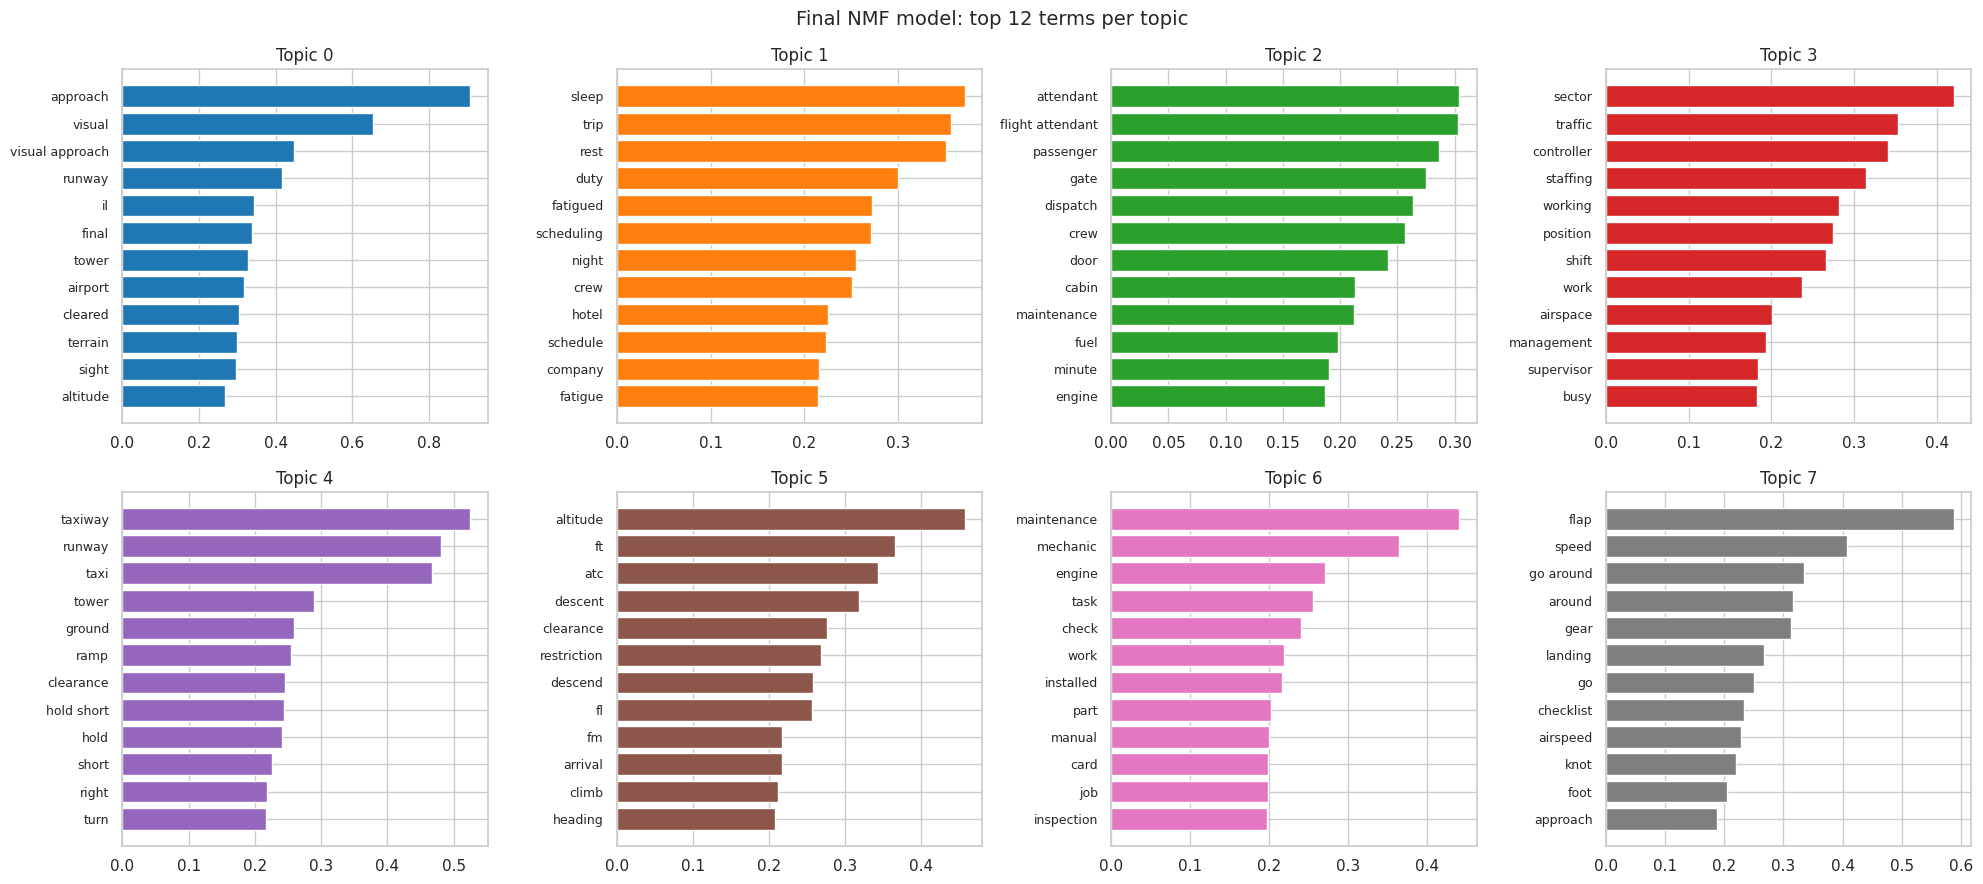

In [18]:
top_n = 12
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for t, ax in enumerate(axes.ravel()[:FINAL_K]):
    ids = np.argsort(-final_model.components_[t])[:top_n]
    ax.barh(vocab[ids][::-1], final_model.components_[t][ids][::-1], color=sns.color_palette("tab10")[t % 10])
    ax.set_title(f"Topic {t}", fontsize=12)
    ax.tick_params(axis="y", labelsize=9)
for ax in axes.ravel()[FINAL_K:]:
    ax.axis("off")
fig.suptitle(f"Final NMF model: top {top_n} terms per topic", fontsize=14)
save("model_02_final_topics_top_terms.png")

### 8.2 Read representative narratives
Numbers alone can't say what a topic *means*. The EDA plan was to **validate each theme by reading the narratives that load most strongly on it**. Below are the beginnings of the two most representative training narratives for each topic.

In [19]:
W_train = final_model.transform(X_tfidf_train)
for t in range(FINAL_K):
    print(f"\n{'=' * 100}\nTOPIC {t}: {', '.join(vocab[np.argsort(-final_model.components_[t])[:8]])}")
    for rank, row in enumerate(np.argsort(-W_train[:, t])[:2], start=1):
        rep = df.loc[train_idx[row]]
        print(f"  [{rank}] ACN {rep['acn']} | {rep['phase_group']} | {rep['reporter_role']}\n      {rep['narrative_1'][:350]}...")


TOPIC 0: approach, visual, visual approach, runway, il, final, tower, airport
  [1] ACN 951251 | Descent & Approach | Pilot
      On Base leg to Runway 1L; we were cleared for the visual approach; the Captain (pilot not flying) accepted the visual approach to 1L. The First Officer (pilot flying) did not have the airport visually and had the incorrect localizer inbound course set in his HSI. I also did not have the runway insight nor did I recognize that the First Officer had ...
  [2] ACN 1942817 | Descent & Approach | Pilot
      After two unsuccessful attempts to land at ZZZ1 Airport due to weather. We diverted to ZZZ where we setup for a visual approach to Runway X. We used the RNAV (GPS) Y Runway X approach to back up the visual approach as the ILS approach was out of service. On right downwind for Runway X ATC asked if we had the airport in sight which we did. They clea...

TOPIC 1: sleep, trip, rest, duty, fatigued, scheduling, night, crew
  [1] ACN 1060590 | Ground | Pilot
    

### 8.3 Naming the themes
Using the top words and the representative narratives, I gave each topic a short label:

| Topic | Label | Top words (summary) | What the representative narratives describe |
|---|---|---|---|
| 0 | **Visual approach & terrain awareness** | approach, visual approach, runway, ILS ("il"), final, tower, terrain, sight | Accepting a visual approach without the airport in sight, wrong localizer course set, approaches after diversions |
| 1 | **Fatigue, rest & crew scheduling** | sleep, trip, rest, duty, fatigued, scheduling, night, hotel | Reporters explaining *why* they were tired: red-eye flights, reserve assignments, multi-day trips, naps that didn't work, calls with crew scheduling |
| 2 | **Gate, cabin & pre-departure operations** | attendant, flight attendant, passenger, gate, dispatch, door, cabin | Delays and pre-departure problems at the gate: MEL deferrals, tarmac delays, flight attendants caring for passengers |
| 3 | **ATC workload & staffing** | sector, traffic, controller, staffing, position, shift, supervisor, busy | Controllers working combined or busy sectors, weather deviations, short staffing, being called back from breaks |
| 4 | **Taxi & runway incursion risk** | taxiway, runway, taxi, tower, ground, ramp, hold short | Confusing taxi routes and clearances, temporary runways, near-incursions on the ground |
| 5 | **Altitude & clearance deviations** | altitude, ft, ATC, descent, clearance, restriction, FL | "Descend via" clearances and crossing restrictions programmed or flown incorrectly during descent and climb |
| 6 | **Maintenance work & task errors** | maintenance, mechanic, engine, task, check, installed, part, card | Overnight maintenance shifts: incomplete installations, missed steps at shift turnover, aircraft released with parts missing |
| 7 | **Approach configuration & go-arounds** | flap, speed, go around, gear, landing, checklist, airspeed | Unstable approaches: speed and flap problems, configuration warnings, and go-arounds by tired crews |

Most topics have good coherence (0.20–0.27 on the test set). The **maintenance** topic is the least coherent (0.11), because technicians describe many different tasks (engines, windows, parts, manuals). It's still clearly nameable and is dominated by maintenance reporters.

> **Your decision point:** these labels come from **my** run. Topic numbers come from the model and should match yours, but compare each label with **your** top-words chart and representative narratives before you keep them. If a topic in your output reads differently, rename it in `TOPIC_LABELS`. Naming the themes is a core part of *your* interpretation.

In [20]:
TOPIC_LABELS = {
    0: "Visual approach & terrain awareness",
    1: "Fatigue, rest & crew scheduling",
    2: "Gate, cabin & pre-departure operations",
    3: "ATC workload & staffing",
    4: "Taxi & runway incursion risk",
    5: "Altitude & clearance deviations",
    6: "Maintenance work & task errors",
    7: "Approach configuration & go-arounds",
}
assert len(TOPIC_LABELS) == FINAL_K, "Update TOPIC_LABELS to match FINAL_K"
for t, label in TOPIC_LABELS.items():
    print(f"Topic {t} -> {label:<42} | {', '.join(vocab[np.argsort(-final_model.components_[t])[:6]])}")

Topic 0 -> Visual approach & terrain awareness        | approach, visual, visual approach, runway, il, final
Topic 1 -> Fatigue, rest & crew scheduling            | sleep, trip, rest, duty, fatigued, scheduling
Topic 2 -> Gate, cabin & pre-departure operations     | attendant, flight attendant, passenger, gate, dispatch, crew
Topic 3 -> ATC workload & staffing                    | sector, traffic, controller, staffing, working, position
Topic 4 -> Taxi & runway incursion risk               | taxiway, runway, taxi, tower, ground, ramp
Topic 5 -> Altitude & clearance deviations            | altitude, ft, atc, descent, clearance, restriction
Topic 6 -> Maintenance work & task errors             | maintenance, mechanic, engine, task, check, work
Topic 7 -> Approach configuration & go-arounds        | flap, speed, go around, around, gear, landing


## 9. Connect the Themes to Report Characteristics

This is Stage 4 of the project plan: **do the narrative themes line up with the structured fields?** I apply the final model to **all 2,191 reports** and give each report:
- a **topic share** for every theme (its topic weights rescaled to add up to 1), and
- a **dominant topic**, the theme with the largest share.

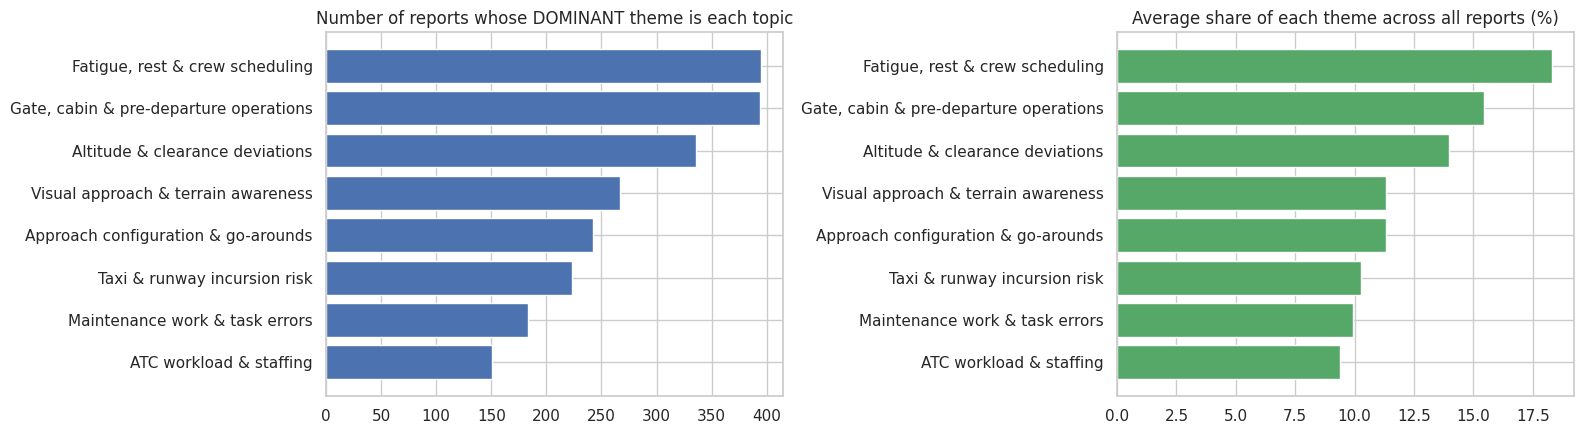

Median share of a report's dominant topic: 0.55
Reports where one theme makes up more than half the narrative: 59.8%


In [21]:
X_all = tfidf.transform(df["text_lemma"])
W_all = final_model.transform(X_all)
shares = W_all / np.clip(W_all.sum(axis=1, keepdims=True), 1e-12, None)
topic_cols = [TOPIC_LABELS[t] for t in range(FINAL_K)]
doc_topics = pd.DataFrame(shares, columns=topic_cols)
doc_topics["dominant_topic"] = shares.argmax(axis=1)
doc_topics["dominant_label"] = doc_topics["dominant_topic"].map(TOPIC_LABELS)
doc_topics["dominant_share"] = shares.max(axis=1)
doc_topics = pd.concat([df[["acn", "year", "phase_group", "time_of_day", "reporter_role", "mission", "operator", "split",
                            "phase_group_model", "time_of_day_model", "reporter_role_model", "mission_model"]], doc_topics], axis=1)

prev = doc_topics["dominant_label"].value_counts()
avg_share = doc_topics[topic_cols].mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].barh(prev.index[::-1], prev.values[::-1], color="#4C72B0")
axes[0].set_title("Number of reports whose DOMINANT theme is each topic")
axes[1].barh(avg_share.index[::-1], avg_share.values[::-1] * 100, color="#55A868")
axes[1].set_title("Average share of each theme across all reports (%)")
save("model_03_topic_prevalence.png")
print("Median share of a report's dominant topic:", round(doc_topics["dominant_share"].median(), 2))
print("Reports where one theme makes up more than half the narrative:", f"{(doc_topics['dominant_share'] > 0.5).mean():.1%}")

**Reading the prevalence charts.** **Fatigue, rest & crew scheduling** is the most common dominant theme (395 reports), just ahead of gate & cabin operations (394) and altitude & clearance deviations (336). Even so, only about 1 in 5 reports is *mainly* about fatigue's causes. Most are mainly about an **operational situation** (approach, altitude, taxi, gate, maintenance or ATC work) in which fatigue played a part. Reports also **mix themes**: a report's main theme makes up a median of 55% of its topic weight, and in 40% of reports no single theme reaches half. That's why NMF, which allows mixtures, fits better than K-Means' one-group-per-report approach.

### 9.1 Themes by flight phase

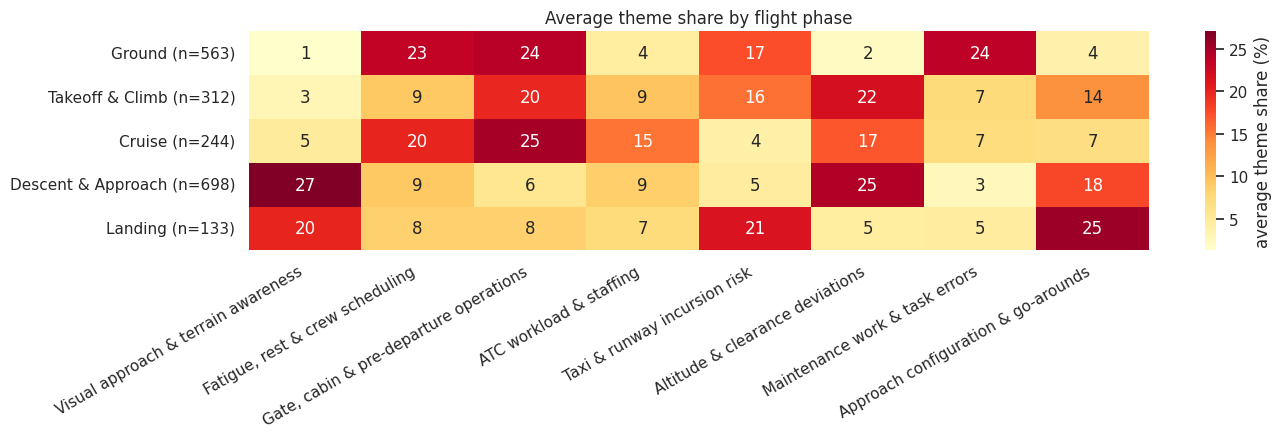

Dominant theme × phase_group: chi2 = 1365.7, dof = 28, p = 3.21e-270, Cramér's V = 0.42


In [22]:
def theme_heatmap(group_col, title, fname, order=None, min_n=50):
    sizes = doc_topics[group_col].value_counts()
    keep = [g for g in (order or sizes.index) if sizes.get(g, 0) >= min_n and g not in ("Unknown", "Other", "Other / Unknown")]
    table = doc_topics[doc_topics[group_col].isin(keep)].groupby(group_col)[topic_cols].mean().loc[keep] * 100
    fig, ax = plt.subplots(figsize=(14, 0.55 * len(keep) + 1.8))
    sns.heatmap(table, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "average theme share (%)"})
    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_yticklabels([f"{g} (n={sizes[g]})" for g in keep], rotation=0)
    plt.xticks(rotation=30, ha="right")
    save(fname)
    sub = doc_topics[doc_topics[group_col].isin(keep)]
    ct = pd.crosstab(sub[group_col], sub["dominant_label"])
    chi2_stat, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2_stat / (n * (min(ct.shape) - 1)))
    print(f"Dominant theme × {group_col}: chi2 = {chi2_stat:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {v:.2f}")
    return table

phase_table = theme_heatmap("phase_group", "Average theme share by flight phase", "model_04_themes_by_phase.png",
                            order=["Ground", "Takeoff & Climb", "Cruise", "Descent & Approach", "Landing"])

**Themes by flight phase.** The association is **moderately strong** (Cramér's V = 0.42), much larger than the phase × time-of-day link found in EDA (0.06). The themes clearly follow the phase of flight:
- **Ground:** *gate & cabin* (24%), *maintenance* (24%), *fatigue, rest & scheduling* (23%) and *taxi & runway* (17%).
- **Takeoff & Climb:** *altitude & clearance* (22%), *gate & cabin* (20%) and *taxi & runway* (16%).
- **Cruise:** *gate & cabin* (25%, largely flight attendants' in-flight reports), *fatigue, rest & scheduling* (20%), *altitude* (17%) and *ATC workload* (15%).
- **Descent & Approach:** *visual approach* (27%), *altitude & clearance* (25%) and *approach configuration* (18%).
- **Landing:** *approach configuration & go-arounds* (25%), *taxi & runway* (21%) and *visual approach* (20%).

This shows that **the text and the structured fields agree**, which supports the validity of the topics. What the text adds is the *how* and *why*. For example, the fatigue-and-scheduling theme shows up in **every** phase (8–23%), so reporters describe fatigue's causes no matter where the event happened.

### 9.2 Themes by time of day and by reporter role

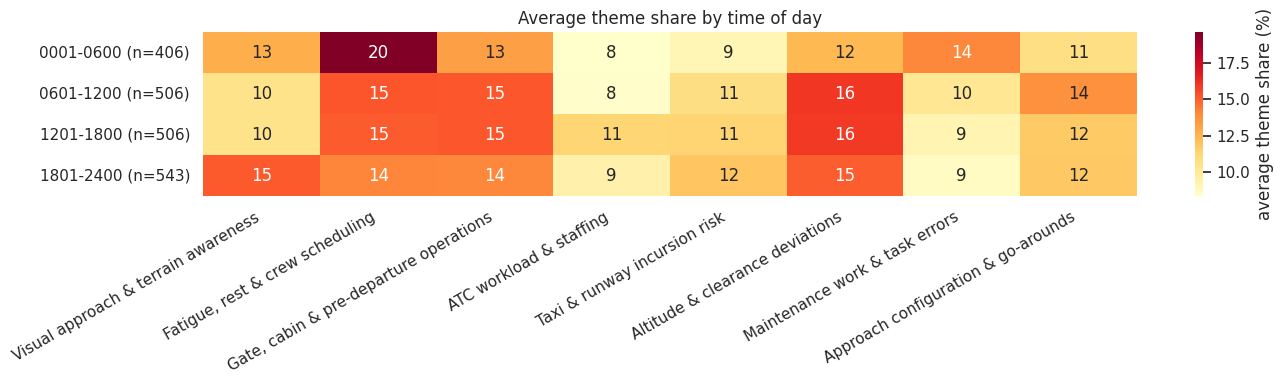

Dominant theme × time_of_day: chi2 = 68.7, dof = 21, p = 5.68e-07, Cramér's V = 0.11


In [23]:
tod_table = theme_heatmap("time_of_day", "Average theme share by time of day", "model_05_themes_by_time.png",
                          order=["0001-0600", "0601-1200", "1201-1800", "1801-2400"])

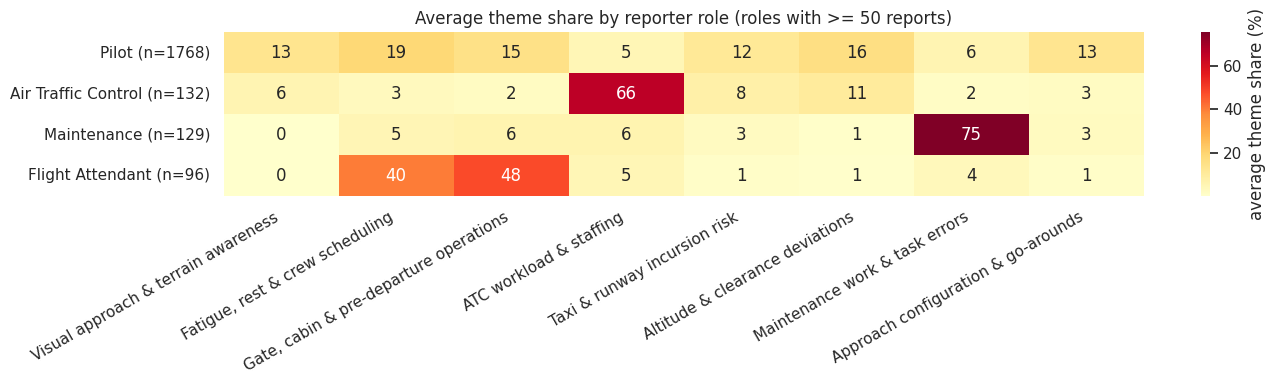

Dominant theme × reporter_role: chi2 = 3011.3, dof = 21, p = 0.00e+00, Cramér's V = 0.69


In [24]:
role_table = theme_heatmap("reporter_role", "Average theme share by reporter role (roles with >= 50 reports)",
                           "model_06_themes_by_role.png",
                           order=["Pilot", "Air Traffic Control", "Maintenance", "Flight Attendant"])

**Themes by time of day.** The association is **weak** (Cramér's V = 0.11), similar to the weak phase × time link in EDA. The pattern worth noting is in the **late-night block (0001–0600)**, which has the highest share of **fatigue, rest & scheduling** (20% vs. 14–15% at other times) and of **maintenance work** (14% vs. 9–10%). That fits overnight maintenance shifts and "back side of the clock" flying. Evening reports (1801–2400) have the most *visual approach* content (15%), consistent with night visual approaches.

**Themes by reporter role.** This is the **strongest association in the project** (Cramér's V = 0.69). Each occupation's narratives are dominated by its own work context:
- **Air traffic controllers:** 66% *ATC workload & staffing*.
- **Maintenance technicians:** 75% *maintenance work & task errors*.
- **Flight attendants:** 48% *gate & cabin* and 40% *fatigue, rest & scheduling*. Flight attendants write about fatigue's *causes* more than any other group.
- **Pilots** spread across every flight-related theme, led by *fatigue, rest & scheduling* (19%), *altitude & clearance* (16%) and *gate & cabin* (15%).

This supports the EDA decision to treat reporter role as a key lens. **Fatigue is described through each occupation's own work.**

### 9.3 Themes by mission

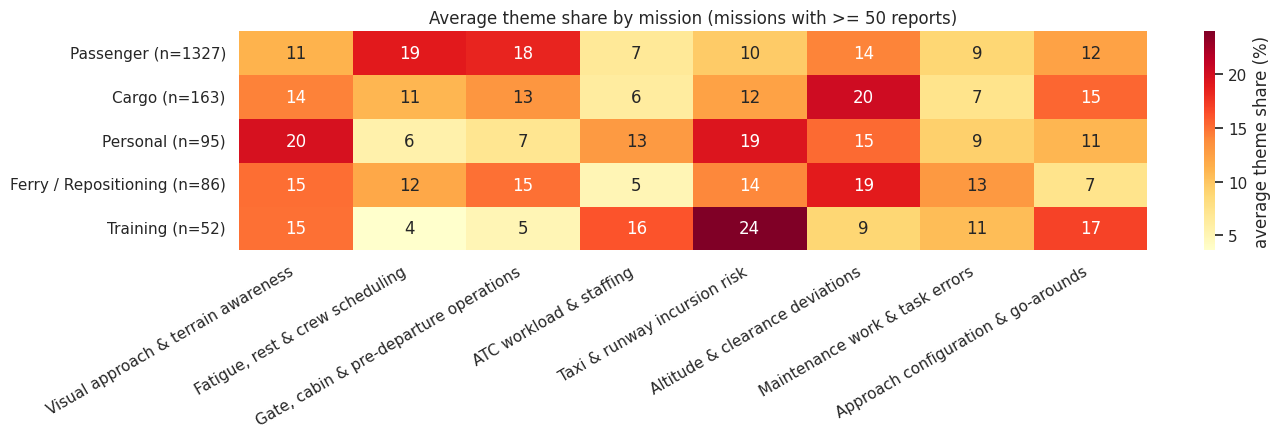

Dominant theme × mission: chi2 = 174.1, dof = 28, p = 4.87e-23, Cramér's V = 0.16


In [25]:
mission_table = theme_heatmap("mission", "Average theme share by mission (missions with >= 50 reports)",
                              "model_07_themes_by_mission.png",
                              order=["Passenger", "Cargo", "Personal", "Ferry / Repositioning", "Training"])

**Themes by mission.** The association is **weak** (Cramér's V = 0.16). **Passenger** flights have the most *fatigue, rest & scheduling* (19%) and *gate & cabin* (18%) content. That's partly because flight attendants only appear on passenger flights. **Cargo** reports lean more toward *altitude & clearance* (20%) and *approach configuration* (15%), and have less scheduling content (11%) than passenger reports. **Personal** and **training** flights (mostly small aircraft) are dominated by *visual approach*, *taxi & runway* (24% for training) and *ATC* themes, and have very little scheduling content (4–6%), because those pilots usually aren't working airline duty schedules. As always, these are shares *within reports*, not rates.

### 9.4 Have the themes changed over time?

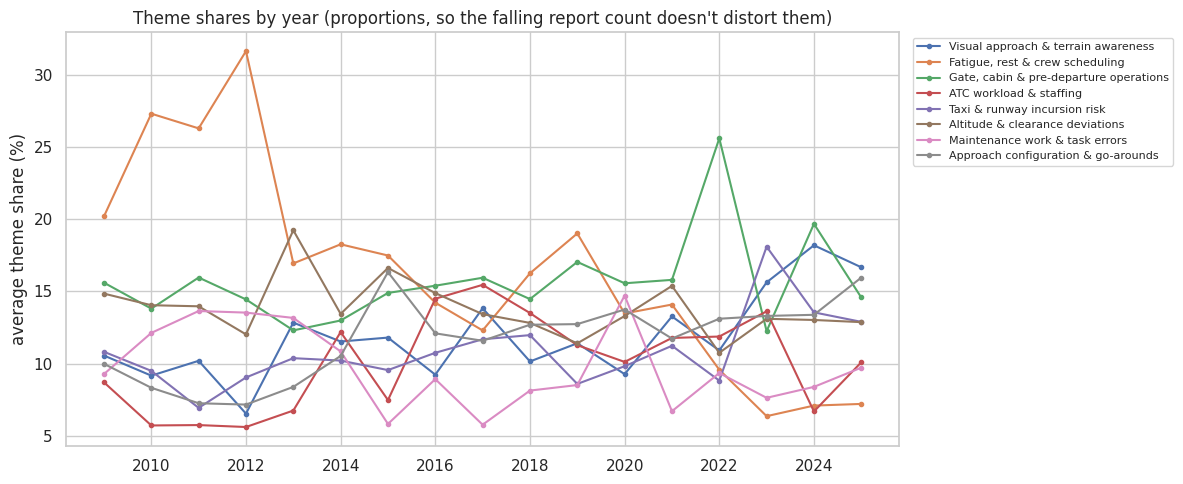

,theme,Kendall tau,p-value,significant (p < 0.05)
1,"Fatigue, rest & crew scheduling",-0.691,0.000,True
5,Altitude & clearance deviations,-0.382,0.034,True
6,Maintenance work & task errors,-0.235,0.205,False
2,"Gate, cabin & pre-departure operations",0.221,0.236,False
3,ATC workload & staffing,0.265,0.151,False
4,Taxi & runway incursion risk,0.368,0.042,True
0,Visual approach & terrain awareness,0.441,0.013,True
7,Approach configuration & go-arounds,0.632,0.000,True


In [26]:
year_share = doc_topics.groupby("year")[topic_cols].mean() * 100
fig, ax = plt.subplots(figsize=(12, 5))
for col in topic_cols:
    ax.plot(year_share.index, year_share[col], marker="o", ms=3, label=col)
ax.set_ylabel("average theme share (%)")
ax.set_title("Theme shares by year (proportions, so the falling report count doesn't distort them)")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save("model_08_themes_by_year.png")

trend = pd.DataFrame([{"theme": col, "Kendall tau": stats.kendalltau(year_share.index, year_share[col])[0],
                       "p-value": stats.kendalltau(year_share.index, year_share[col])[1]} for col in topic_cols])
trend["significant (p < 0.05)"] = trend["p-value"] < 0.05
display(trend.sort_values("Kendall tau").round(3))

**Interpretation.** Five themes have a significant trend in their share of reports:
- **Fatigue, rest & crew scheduling has fallen sharply** (Kendall's tau = −0.69). It made up 20–32% of report content in 2009–2012, but only 6–7% in 2023–2025.
- *Altitude & clearance deviations* have also declined (tau = −0.38).
- *Approach configuration & go-arounds* (tau = 0.63), *visual approach* (0.44) and *taxi & runway* (0.37) have risen.

In other words, over time fatigue reports talk **less about schedules and rest** and **more about the operational event itself**. One possible explanation is the FAA's pilot flight, duty and rest rules (14 CFR Part 117), which took effect in January 2014. The drop in the scheduling theme begins around 2013. But changes in who reports, in ASRS coding, and in which reports NASA fully processes could also explain it. With only 17 yearly points, this is a **finding worth further research, not proof of a policy effect**.

## 10. Integration Model: Can Report Characteristics Predict the Theme?

This is where the **dummy features, scaled numerics and train/test split** from Step 4 come in. The question is: **if we only knew a report's structured fields (flight phase, time of day, reporter role, mission, operator, year, narrative length and coded human factors), how well could we predict its dominant narrative theme?**
- If prediction is **very accurate**, the narratives mostly repeat what the coded fields already say.
- If prediction is **only moderately better than chance**, the narratives contain information the coded fields **don't capture**. That would show the value of NLP for aviation safety analysis.

**Model:** multinomial logistic regression with L2 regularization. `class_weight="balanced"` stops the model from ignoring smaller themes. **Tuning:** the regularization strength `C` is chosen by 5-fold stratified cross-validation on the training set. **Metric:** **macro F1** (the average F1 across all themes, so each theme counts equally), with accuracy also reported. **Baselines:** always guessing the most common theme, and guessing at random in proportion to theme frequency.

In [27]:
y_train = doc_topics.loc[train_idx, "dominant_topic"].values
y_test = doc_topics.loc[test_idx, "dominant_topic"].values
feature_cols = [c for c in X_struct_train.columns if c != "acn"]
Xs_train, Xs_test = X_struct_train[feature_cols].values, X_struct_test[feature_cols].values

grid = GridSearchCV(
    LogisticRegression(max_iter=3000, class_weight="balanced"),
    param_grid={"C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    scoring="f1_macro", cv=StratifiedKFold(5, shuffle=True, random_state=42),
)
grid.fit(Xs_train, y_train)
cv_table = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score"]].round(3)
cv_table.columns = ["C", "CV macro F1 (mean)", "CV macro F1 (SD)"]
display(cv_table)
print("Best C:", grid.best_params_["C"])

,C,CV macro F1 (mean),CV macro F1 (SD)
0,0.01,0.539,0.029
1,0.03,0.569,0.021
2,0.10,0.576,0.023
3,0.30,0.575,0.033
4,1.00,0.571,0.037
5,3.00,0.564,0.032


Best C: 0.1


In [28]:
clf = grid.best_estimator_
pred = clf.predict(Xs_test)
base_major = DummyClassifier(strategy="most_frequent").fit(Xs_train, y_train).predict(Xs_test)
base_strat = DummyClassifier(strategy="stratified", random_state=42).fit(Xs_train, y_train).predict(Xs_test)

integration_scores = pd.DataFrame({
    "accuracy": [accuracy_score(y_test, base_major), accuracy_score(y_test, base_strat), accuracy_score(y_test, pred)],
    "macro F1": [f1_score(y_test, base_major, average="macro"), f1_score(y_test, base_strat, average="macro"),
                 f1_score(y_test, pred, average="macro")],
}, index=["Baseline: most frequent theme", "Baseline: random by frequency", "Logistic regression (tuned)"]).round(3)
display(integration_scores)
print(classification_report(y_test, pred, target_names=[TOPIC_LABELS[t] for t in range(FINAL_K)], zero_division=0))

,accuracy,macro F1
Baseline: most frequent theme,0.159,0.034
Baseline: random by frequency,0.134,0.128
Logistic regression (tuned),0.554,0.575


                                        precision    recall  f1-score   support

   Visual approach & terrain awareness       0.43      0.58      0.50        57
       Fatigue, rest & crew scheduling       0.73      0.63      0.68        70
Gate, cabin & pre-departure operations       0.69      0.58      0.63        92
               ATC workload & staffing       0.78      0.82      0.80        22
          Taxi & runway incursion risk       0.42      0.61      0.50        44
       Altitude & clearance deviations       0.42      0.32      0.36        69
        Maintenance work & task errors       0.91      0.73      0.81        41
   Approach configuration & go-arounds       0.30      0.36      0.33        44

                              accuracy                           0.55       439
                             macro avg       0.59      0.58      0.58       439
                          weighted avg       0.58      0.55      0.56       439



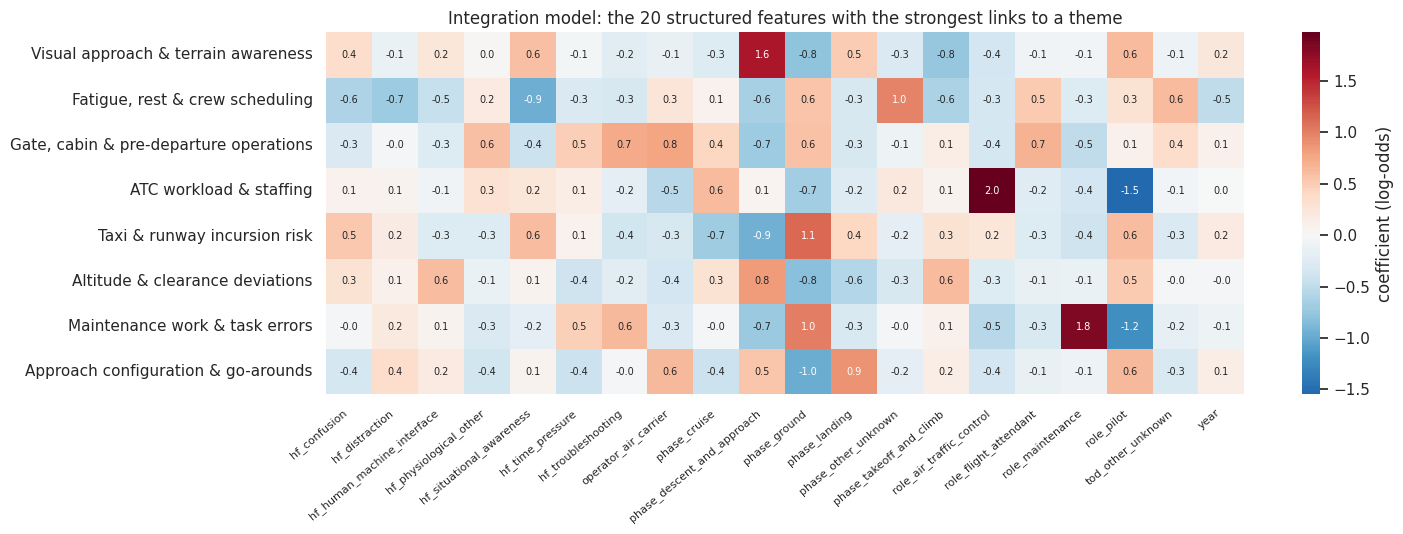

In [29]:
coefs = pd.DataFrame(clf.coef_, index=[TOPIC_LABELS[t] for t in clf.classes_], columns=feature_cols)
top_feats = sorted(set(coefs.abs().max(axis=0).sort_values(ascending=False).index[:20]))
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(coefs[top_feats], cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "coefficient (log-odds)"})
ax.set_title("Integration model: the 20 structured features with the strongest links to a theme")
plt.xticks(rotation=40, ha="right", fontsize=8)
save("model_09_integration_coefficients.png")

**What the integration model shows:**
- The tuned logistic regression (best C = 0.1) reaches a **test macro F1 of 0.58 and accuracy of 0.55**. That's far better than both baselines (macro F1 0.03 and 0.13) and close to its cross-validation score (0.58), so it isn't overfitting. **The coded fields and the narrative themes clearly overlap**, which matches Section 9.
- But it's **far from perfect**: it misses about 45% of test reports. The **easiest themes to predict** are the occupation-specific ones: *maintenance* (F1 0.81) and *ATC workload* (0.80), because reporter role almost gives them away. The **hardest** are the pilot flight-deck themes: *approach configuration* (0.33), *altitude & clearance* (0.36), *visual approach* and *taxi* (0.50). Phase, time and coded human factors can't tell apart the specific situations pilots describe, such as a flap warning vs. a missed crossing restriction during the same descent. **That detail exists only in the narratives**, which is the main argument for using NLP on safety reports.
- **The coefficients** show which fields point toward which theme:
  - *ATC reporter* → ATC workload (+2.0); *maintenance reporter* → maintenance (+1.8).
  - *Descent & approach* → visual approach (+1.6); *ground* → taxi (+1.1) and maintenance (+1.0).
  - *Troubleshooting* → gate (+0.7) and maintenance (+0.6).
  - *Situational awareness* → visual approach and taxi (+0.6), but *away from* the fatigue/scheduling theme (−0.9). Reports that mainly discuss rest and schedules tend to have fewer other human factors coded.
  - *Unknown flight phase* → fatigue/scheduling (+1.0). Reports about scheduling often aren't tied to a specific flight event.
  - *Year* → fatigue/scheduling is negative (−0.5), matching the downward trend in 9.4.

  These are **associations, not causes**.

## 11. Save the Final Model and Metrics

In [30]:
joblib.dump(final_model, os.path.join(MODEL_DIR, "final_nmf_model.joblib"))
joblib.dump(clf, os.path.join(MODEL_DIR, "integration_logreg.joblib"))
doc_topics.to_csv(os.path.join(PROCESSED_DIR, "report_topics.csv"), index=False)
res.round(4).to_csv(os.path.join(MODEL_DIR, "model_comparison_metrics.csv"), index=False)

topic_table = pd.DataFrame({
    "topic": range(FINAL_K),
    "label": [TOPIC_LABELS[t] for t in range(FINAL_K)],
    "top_terms": [", ".join(vocab[np.argsort(-final_model.components_[t])[:12]]) for t in range(FINAL_K)],
    "coherence_test": [npmi_coherence(ids) for ids in top_term_ids(final_model.components_)],
    "n_reports_dominant": [int((doc_topics["dominant_topic"] == t).sum()) for t in range(FINAL_K)],
    "avg_share_pct": [round(100 * doc_topics[TOPIC_LABELS[t]].mean(), 1) for t in range(FINAL_K)],
})
topic_table.to_csv(os.path.join(MODEL_DIR, "final_topics.csv"), index=False)
display(topic_table.round(3))

summary_lines = [
    "FINAL MODEL SUMMARY: Capstone Three (ASRS fatigue-related reports)",
    "",
    "Final model: Non-negative Matrix Factorization (scikit-learn NMF)",
    f"  n_components (topics) = {FINAL_K}; init = nndsvda; max_iter = 1000; random_state = 42",
    "Input features: TF-IDF of lemmatized primary narratives",
    f"  ngram_range = (1, 2); min_df = 5; max_df = 0.5; sublinear_tf = True; vocabulary = {len(vocab)} terms",
    f"Train/test split: {len(train_idx)} / {len(test_idx)} reports, stratified by flight phase, random_state = 42",
    "",
    "Performance metrics (final model):",
    f"  Topic coherence NPMI (test) = {final_row['coherence_test']:.3f}; (train) = {coh_train:.3f}",
    f"  Topic diversity (top 25) = {final_row['diversity']:.3f}",
    f"  Stability across seeds (Jaccard, top 10) = {final_row['stability']:.3f}",
    "",
    "Models compared: NMF, LDA (two alpha settings), K-Means; k = 4 to 14 (see model_comparison_metrics.csv)",
    "",
    "Integration model: multinomial logistic regression (L2, class_weight = balanced)",
    f"  Best C (5-fold CV, macro F1) = {grid.best_params_['C']}",
    f"  Test accuracy = {integration_scores.loc['Logistic regression (tuned)', 'accuracy']:.3f}; "
    f"test macro F1 = {integration_scores.loc['Logistic regression (tuned)', 'macro F1']:.3f}",
    f"  Baseline (most frequent) macro F1 = {integration_scores.loc['Baseline: most frequent theme', 'macro F1']:.3f}",
    "",
    "Topics:",
] + [f"  {t}: {TOPIC_LABELS[t]} | {', '.join(vocab[np.argsort(-final_model.components_[t])[:8]])}" for t in range(FINAL_K)]
with open(os.path.join(MODEL_DIR, "final_model_summary.txt"), "w") as f:
    f.write("\n".join(summary_lines))
print("\n".join(summary_lines))

,topic,label,top_terms,coherence_test,n_reports_dominant,avg_share_pct
0,0,Visual approach & terrain awareness,"approach, visual, visual approach, runway, il, final, tower, airport, cleared, terrain, sight, altitude",0.233,267,11.3
1,1,"Fatigue, rest & crew scheduling","sleep, trip, rest, duty, fatigued, scheduling, night, crew, hotel, schedule, company, fatigue",0.231,395,18.3
2,2,"Gate, cabin & pre-departure operations","attendant, flight attendant, passenger, gate, dispatch, crew, door, cabin, maintenance, fuel, minute, engine",0.268,394,15.4
3,3,ATC workload & staffing,"sector, traffic, controller, staffing, working, position, shift, work, airspace, management, supervisor, busy",0.209,151,9.4
4,4,Taxi & runway incursion risk,"taxiway, runway, taxi, tower, ground, ramp, clearance, hold short, hold, short, right, turn",0.268,223,10.3
5,5,Altitude & clearance deviations,"altitude, ft, atc, descent, clearance, restriction, descend, fl, fm, arrival, climb, heading",0.196,336,14.0
6,6,Maintenance work & task errors,"maintenance, mechanic, engine, task, check, work, installed, part, manual, card, job, inspection",0.110,183,9.9
7,7,Approach configuration & go-arounds,"flap, speed, go around, around, gear, landing, go, checklist, airspeed, knot, foot, approach",0.249,242,11.3


FINAL MODEL SUMMARY: Capstone Three (ASRS fatigue-related reports)

Final model: Non-negative Matrix Factorization (scikit-learn NMF)
  n_components (topics) = 8; init = nndsvda; max_iter = 1000; random_state = 42
Input features: TF-IDF of lemmatized primary narratives
  ngram_range = (1, 2); min_df = 5; max_df = 0.5; sublinear_tf = True; vocabulary = 9925 terms
Train/test split: 1752 / 439 reports, stratified by flight phase, random_state = 42

Performance metrics (final model):
  Topic coherence NPMI (test) = 0.221; (train) = 0.243
  Topic diversity (top 25) = 0.875
  Stability across seeds (Jaccard, top 10) = 1.000

Models compared: NMF, LDA (two alpha settings), K-Means; k = 4 to 14 (see model_comparison_metrics.csv)

Integration model: multinomial logistic regression (L2, class_weight = balanced)
  Best C (5-fold CV, macro F1) = 0.1
  Test accuracy = 0.554; test macro F1 = 0.575
  Baseline (most frequent) macro F1 = 0.034

Topics:
  0: Visual approach & terrain awareness | approac

## 12. Summary of Modeling

**Models built and compared (all fit on the same 1,752 training narratives and evaluated on the same 439 test narratives):**

| Model | Tuned | Best test coherence | Diversity | Stability | Verdict |
|---|---|---|---|---|---|
| **NMF** | k = 4–14 | **0.226 (0.221 at k = 8)** | **0.81–0.96** | **1.0 at k = 8 and 10** | **Final model** |
| LDA | k = 4–14 × alpha (1/k, 0.1) | 0.165 | below 0.80 from k = 6 | 0.45 | Topics overlap and change between runs |
| K-Means | k = 4–14 | 0.211 | below 0.80 from k = 8 | 0.52–0.72 | Silhouette near 0; reports mix themes, so one-cluster-per-report doesn't fit |

**Final model: NMF with 8 topics**, chosen because it had the best test coherence, diversity and stability, and because k = 8 gave the clearest nameable themes. Coherence held up on unseen reports, so the themes generalize.

**The 8 themes** of fatigue-related ASRS reports: visual approach & terrain awareness; fatigue, rest & crew scheduling; gate, cabin & pre-departure operations; ATC workload & staffing; taxi & runway incursion risk; altitude & clearance deviations; maintenance work & task errors; and approach configuration & go-arounds.

**What the themes tell us (answering the research question):**
1. Fatigue-related reports are mostly about **operational situations in which fatigue played a part**, plus one major theme about **fatigue's causes**: rest, sleep, duty length and crew scheduling (the most common dominant theme, at about 1 in 5 reports).
2. Themes follow **flight phase** (V = 0.42) and especially **reporter role** (V = 0.69). Controllers, technicians, flight attendants and pilots each describe fatigue through their own work.
3. **Late-night** reports carry the most rest/scheduling and maintenance content. **Flight attendants** write about fatigue's causes more than any other group.
4. Over 2009–2025, the **rest and scheduling theme declined sharply** while approach, landing and taxi themes grew. That's worth investigating against the 2014 FAA rest rules.
5. Coded fields predict a report's theme much better than chance (macro F1 0.58 vs. 0.13), but not fully. **The narratives contain detail, especially about pilots' flight-deck situations, that the coded fields don't capture.**

**Limitations:** voluntary reporting (selection bias); no exposure denominator, so all findings are shares *within* reports, not rates; topic labels require human judgment; ASRS coding may have changed over time; and small groups (dispatchers, drone operators, military) are too small to model separately.

**Saved for the final report:** `models/final_nmf_model.joblib`, `models/final_topics.csv`, `models/model_comparison_metrics.csv`, `models/final_model_summary.txt`, `data/processed/report_topics.csv`, and all figures in `figures/`.